<p style="font-size:11px;"><em><strong>Créditos</strong>: El contenido de este cuaderno ha sido tomado de varias fuentes, pero especialmente de <a href="http://darribas.org/">Dani Arribas-Bel</a> - University of Liverpool & <a href="http://spatial.ucr.edu/peopleRey.html">Sergio Rey</a> - Center for Geospatial Sciences, University of California, Riverside. El compilador se disculpa por cualquier omisión involuntaria y estaría encantado de agregar un reconocimiento.</em></p>

# Regresión Ponderada Geográficamente (GWR)

Los Modelos de Regresión Espacial Ponderados (GWR, por sus siglas en inglés) constituyen una herramienta estadística avanzada desarrollada para analizar la heterogeneidad espacial de relaciones entre una variable respuesta y un conjunto de variables predictoras en un contexto geográfico (Brunsdon 1996, Fotheringham 2000, Fotheringham 2009). A diferencia de los modelos de regresión tradicional, que asumen que la relación entre las variables es constante en todo el espacio de estudio, los modelos GWR permiten que los coeficientes varíen de manera local. Esto se logra ajustando un modelo de regresión independiente en cada ubicación geográfica, utilizando datos cercanos para ponderar las estimaciones (Brunsdon 1996). Esta metodología es particularmente valiosa para el análisis de susceptibilidad a movimientos en masa, ya que permite representar cómo las diferentes condiciones del terreno afectan la susceptibilidad de manera no uniforme a lo largo de un área.

La formulación matemática de un modelo de regresión espacial ponderada es de la siguiente forma (Brunsdon 1996):


$$y_i = \beta_0(u_i, v_i) + \sum_{k=1}^p \beta_k(u_i, v_i) x_{ik} + \epsilon_i$$


donde: \( y_i \) es el valor de la variable respuesta en la ubicación \( i \), \( (u_i, v_i) \) las coordenadas geográficas de la ubicación \( i \), \( \beta_0(u_i, v_i) \) el término independiente local en la ubicación \( i \), \( \beta_k(u_i, v_i) \) el coeficiente local asociado con la variable predictora \( x_{ik} \) en la ubicación \( i \). \( x_{ik} \) es el valor de la variable predictora \( k \) para la ubicación \( i \), y \( \epsilon_i \) el término de error en la ubicación \( i \).

Los modelos GWR son útiles en situaciones donde la influencia de las variables predictoras cambia espacialmente (Fotheringham 2009), es decir. En estudios de movimientos en masa, estas relaciones pueden depender de la topografía local, las características del suelo, la vegetación, o incluso de los patrones de precipitación que varían en el espacio. Por ejemplo, la influencia de la pendiente o la cobertura vegetal sobre la susceptibilidad a movimientos en masa puede ser distinta en regiones con diferentes características geológicas o climáticas. La aplicación de GWR permite capturar esta variabilidad y proporciona un análisis más detallado y específico para cada localidad del área de estudio.

El aspecto clave de la GWR es que los coeficientes  varían dependiendo de la ubicación geográfica , lo cual se logra a través del uso de un kernel de ponderación que da más peso a las observaciones cercanas y menos peso a las observaciones lejanas (Fotheringham 2000). En la práctica, este kernel suele ser una función gaussiana o una función adaptativa, que ajusta el peso según la distancia desde el punto central.

Una de las principales ventajas de los modelos GWR es la facilidad con la que los resultados de GWR pueden ser interpretados y visualizados en un contexto espacial, facilitando la identificación de patrones locales de susceptibilidad y ayudando a la toma de decisiones. Los mapas de coeficientes permiten identificar áreas donde ciertas variables tienen una mayor o menor influencia, aportando información útil para el manejo territorial y la planificación.

Sin embargo, los modelos GWR también presentan limitaciones importantes. Una de ellas es la multicolinealidad local, ya que, debido a la naturaleza local de las regresiones, es posible que en algunas áreas las variables predictoras estén altamente correlacionadas, lo que dificulta la interpretación de los coeficientes (Fotheringham 2000, Brunsdon 1996). Además, los modelos GWR suelen ser computacionalmente más exigentes que los modelos de regresión globales o clásicos, especialmente cuando se trabaja con grandes volúmenes de datos espaciales.

Otra limitación a destacar es la selección del ancho de banda (BW) del kernel de ponderación (Guo 2008). El BW determina cuántas observaciones se consideran en el cálculo de los coeficientes locales, y su elección tiene un impacto en los resultados del modelo. Un BW demasiado amplio puede resultar en un modelo más similar a una regresión global, mientras que un BW muy estrecho puede llevar a resultados sobre-ajustados y poco generalizables. La selección adecuada del BW suele requerir un proceso iterativo y cuidadoso.

## Objetivos de aprendizaje

Al finalizar este notebook, el estudiante será capaz de:

- Comprender el principio de no-estacionariedad espacial: coeficientes que varían en el espacio.
- Ajustar un modelo GWR (Geographically Weighted Regression) con `mgwr` y seleccionar el ancho de banda óptimo.
- Extender el GWR al MGWR (Multiscale GWR), donde cada predictor tiene su propia escala espacial.
- Mapear e interpretar los coeficientes localmente variables de cada covariable.
- Identificar las escalas espaciales de cada predictor y relacionarlas con procesos geomorfológicos.

**Requisitos previos:** `09_SpatialRegression` — regresión espacial OLS; `07_MatrizCorrelacion` — autocorrelación espacial.

## Marco teórico ampliado

### Del modelo global al local: limitaciones del OLS

El modelo OLS asume **estacionariedad espacial**: los coeficientes $\beta_k$ son constantes en todo el territorio de estudio:

$$y_i = \beta_0 + \sum_{k=1}^p \beta_k x_{ik} + \epsilon_i$$

La **heterogeneidad espacial** ocurre cuando la fuerza o la dirección de las relaciones varía de una localización a otra (Fotheringham et al., 2002). Un modelo global promedia estas variaciones y puede enmascarar patrones localmente importantes: por ejemplo, el efecto de la pendiente sobre los deslizamientos puede ser muy distinto en zonas con suelos cohesivos respecto de zonas con roca dura.

> **Señal diagnóstica clave**: si los residuos del OLS presentan **autocorrelación espacial** significativa (I de Moran > 0), el modelo está mal especificado y la transición a GWR está justificada. El GWR transforma la dependencia espacial de un *problema* estadístico en el *objeto central* del análisis, operacionalizando directamente la **Primera Ley de Tobler**: *"todo está relacionado con todo, pero las cosas cercanas están más relacionadas que las lejanas"*.

---

### Estimador GWR: mínimos cuadrados ponderados locales

Para cada punto de regresión $i$, GWR estima un modelo propio ponderando las observaciones por proximidad. La **forma matricial del estimador** es:

$$\hat{\boldsymbol{\beta}}(i) = \left(\mathbf{X}^T \mathbf{W}(i) \mathbf{X}\right)^{-1} \mathbf{X}^T \mathbf{W}(i) \mathbf{Y}$$

donde $\mathbf{W}(i)$ es una **matriz diagonal** cuyos elementos $w_{ij}$ son los pesos de cada observación $j$ basados en su distancia a la localización $i$. El proceso se repite para cada punto del área de estudio, produciendo una **superficie de coeficientes** — no valores únicos — que puede mapearse e interpretarse espacialmente.

---

### Funciones kernel y selección del ancho de banda

#### Funciones kernel disponibles en `mgwr`

| Kernel | Comportamiento | Cuándo usar |
|--------|---------------|-------------|
| **Gaussiano** | Decaimiento suave y continuo; toda observación recibe algún peso | Procesos con influencia gradual entre localidades |
| **Bisquare** | Pesos = 0 fuera del radio BW; vecindad con corte abrupto | Cuando se desea un vecindario bien delimitado |

#### Balance sesgo–varianza del ancho de banda (*bandwidth*, BW)

| BW pequeño | BW grande |
|------------|----------|
| Captura variaciones locales finas | Estimaciones más estables y suaves |
| Alta varianza, riesgo de sobreajuste | Alto sesgo |
| Sensible al ruido local | Cuando BW → ∞, GWR converge al OLS global |

**Selección óptima automática**: se minimiza el **AICc** (*Corrected Akaike Information Criterion*), que premia la bondad de ajuste mientras penaliza la complejidad del modelo.

#### Kernel fijo vs. adaptativo

| Tipo | Definición del BW | `mgwr` | Cuándo usar |
|------|------------------|--------|-------------|
| **Fijo** | Radio de búsqueda constante (ej. 50 000 m) | `fixed=True` | Datos distribuidos uniformemente en el espacio |
| **Adaptativo** | $k$ vecinos más cercanos; radio variable por punto | `fixed=False` | **Datos con distribución espacial irregular** |

Para datos geomorfológicos con distribución irregular — cuencas de diferente tamaño, inventarios de deslizamientos concentrados en valles — el **kernel adaptativo** es más robusto: garantiza que cada regresión local se calibre con una cantidad consistente de información, evitando estimaciones inestables en regiones con escasos datos.


In [12]:
import libpysal as ps
import numpy
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn
import numpy as np

El conjunto de datos de Georgia consta de 159 condados en el estado de Georgia, y registra características sociodemográficas del censo de EE. UU. de 1990.


In [ ]:
georgia_data = pd.read_csv(ps.examples.get_path('GData_utm.csv'))
georgia_shp = gpd.read_file(ps.examples.get_path('G_utm.shp'))

<Axes: >

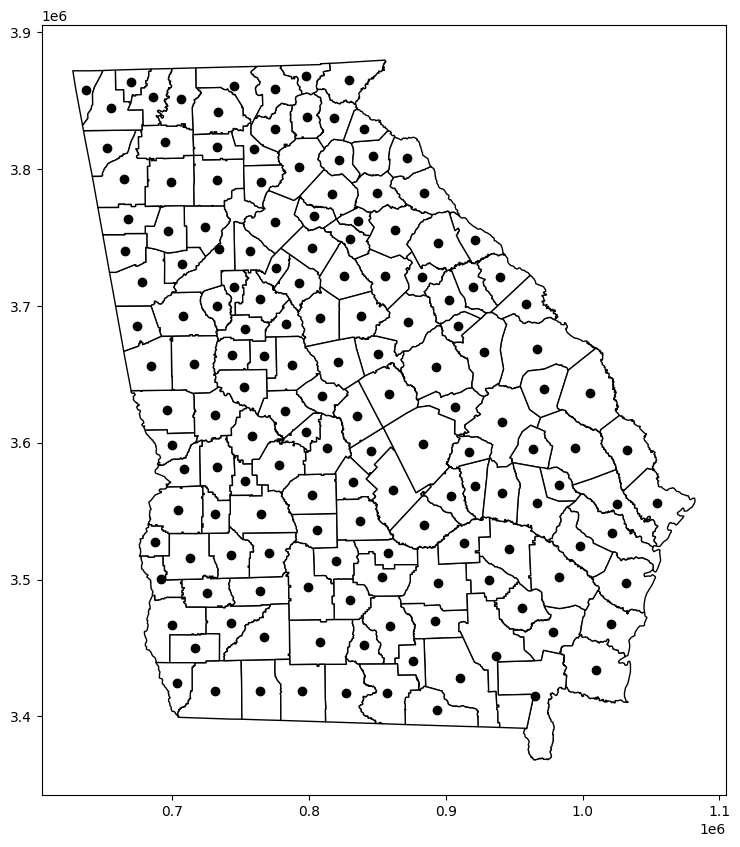

In [ ]:
fig, ax = plt.subplots(figsize=(10,10))
georgia_shp.plot(ax=ax, **{'edgecolor':'black', 'facecolor':'white'})
georgia_shp.centroid.plot(ax=ax, c='black')

In [ ]:
georgia_shp.head(2)

,AREA,PERIMETER,G_UTM_,G_UTM_ID,Latitude,Longitud,TotPop90,PctRural,PctBach,PctEld,PctFB,PctPov,PctBlack,X,Y,AreaKey,geometry
0,1.331370e+09,207205.0,132,133,31.75339,-82.28558,15744,75.6,8.2,11.43,0.64,19.9,20.76,941396.6,3521764,13001,"POLYGON ((931869.062 3545540.500, 934111.625 3..."
1,8.929300e+08,154640.0,157,158,31.29486,-82.87474,6213,100.0,6.4,11.77,1.58,26.0,26.86,895553.0,3471916,13003,"POLYGON ((867016.312 3482416.000, 884309.375 3..."


In [ ]:
georgia_shp.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 159 entries, 0 to 158
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype   
---  ------     --------------  -----   
 0   AREA       159 non-null    float64 
 1   PERIMETER  159 non-null    float64 
 2   G_UTM_     159 non-null    int64   
 3   G_UTM_ID   159 non-null    int64   
 4   Latitude   159 non-null    float64 
 5   Longitud   159 non-null    float64 
 6   TotPop90   159 non-null    int64   
 7   PctRural   159 non-null    float64 
 8   PctBach    159 non-null    float64 
 9   PctEld     159 non-null    float64 
 10  PctFB      159 non-null    float64 
 11  PctPov     159 non-null    float64 
 12  PctBlack   159 non-null    float64 
 13  X          159 non-null    float64 
 14  Y          159 non-null    int64   
 15  AreaKey    159 non-null    int64   
 16  geometry   159 non-null    geometry
dtypes: float64(11), geometry(1), int64(5)
memory usage: 21.2 KB


In [ ]:
#Prepare Georgia dataset inputs
g_y = georgia_data['PctBach'].values.reshape((-1,1))
g_X = georgia_data[['PctFB', 'PctBlack', 'PctRural']].values
u = georgia_data['X']
v = georgia_data['Y']
g_coords = list(zip(u,v))


In [ ]:
# estandarizar datos
g_X = (g_X - g_X.mean(axis=0)) / g_X.std(axis=0)
g_y = g_y.reshape((-1,1))
g_y = (g_y - g_y.mean(axis=0)) / g_y.std(axis=0)

In [ ]:
#Calibrate GWR model
from mgwr.gwr import GWR, MGWR
from mgwr.sel_bw import Sel_BW

gwr_selector = Sel_BW(g_coords, g_y, g_X)
gwr_bw = gwr_selector.search(bw_min=2)
print(gwr_bw)

117.0


In [ ]:
gwr_results = GWR(g_coords, g_y, g_X, gwr_bw).fit()

In [ ]:
np.shape(gwr_results.params)

(159, 4)

In [ ]:
gwr_results.params[0:5]

array([[-0.23204579,  0.22820815,  0.05697445, -0.42649461],
       [-0.2792238 ,  0.16511734,  0.09516542, -0.41226348],
       [-0.248944  ,  0.20466991,  0.07121197, -0.42573638],
       [-0.23036768,  0.1527493 ,  0.0510379 , -0.35938659],
       [ 0.19066196,  0.71627541, -0.16920186, -0.24091753]])

In [ ]:
gwr_results.localR2[0:10]

array([[0.55932878],
       [0.5148705 ],
       [0.54751792],
       [0.50691577],
       [0.69062134],
       [0.69429812],
       [0.69813709],
       [0.70867337],
       [0.49985703],
       [0.49379842]])

In [ ]:
np.float = np.float64
gwr_results.summary()

Model type                                                         Gaussian
Number of observations:                                                 159
Number of covariates:                                                     4

Global Regression Results
---------------------------------------------------------------------------
Residual sum of squares:                                             71.793
Log-likelihood:                                                    -162.399
AIC:                                                                332.798
AICc:                                                               335.191
BIC:                                                               -713.887
R2:                                                                   0.548
Adj. R2:                                                              0.540

Variable                              Est.         SE  t(Est/SE)    p-value
------------------------------- ---------- ---------- ------

In [ ]:
#Prepare GWR results for mapping

#Add GWR parameters to GeoDataframe
georgia_shp['gwr_intercept'] = gwr_results.params[:,0]
georgia_shp['gwr_fb'] = gwr_results.params[:,1]
georgia_shp['gwr_aa'] = gwr_results.params[:,2]
georgia_shp['gwr_rural'] = gwr_results.params[:,3]

#Obtain t-vals filtered based on multiple testing correction
gwr_filtered_t = gwr_results.filter_tvals()

<Axes: >

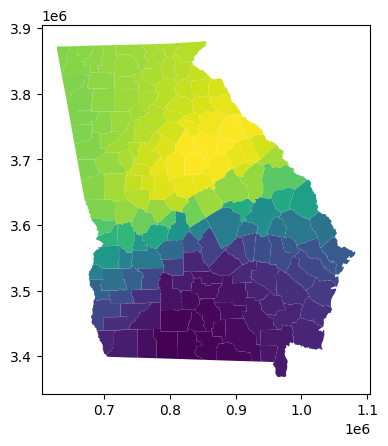

In [ ]:
georgia_shp.plot(column='gwr_intercept')

<Axes: >

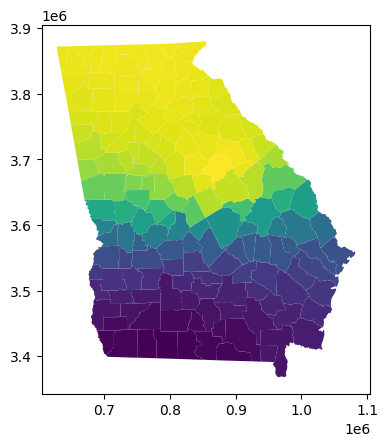

In [ ]:
georgia_shp.plot(column='gwr_fb')

<Axes: >

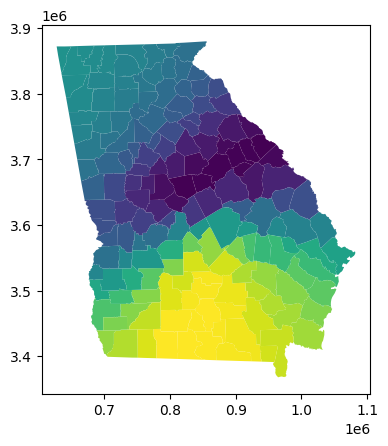

In [ ]:
georgia_shp.plot(column='gwr_aa')

<Axes: >

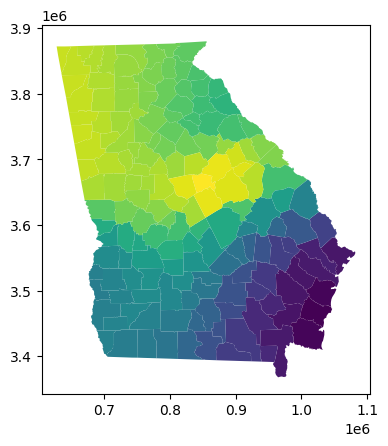

In [ ]:
georgia_shp.plot(column='gwr_rural')

### Regresión Ponderada Geográficamente Multiescala (MGWR)

In [ ]:
#Calibrate MGWR model

mgwr_selector = Sel_BW(g_coords, g_y, g_X, multi=True)
mgwr_bw = mgwr_selector.search(multi_bw_min=[2])
mgwr_results = MGWR(g_coords, g_y, g_X, mgwr_selector).fit()

In [ ]:
mgwr_results.summary()

Model type                                                         Gaussian
Number of observations:                                                 159
Number of covariates:                                                     4

Global Regression Results
---------------------------------------------------------------------------
Residual sum of squares:                                             71.793
Log-likelihood:                                                    -162.399
AIC:                                                                332.798
AICc:                                                               335.191
BIC:                                                               -713.887
R2:                                                                   0.548
Adj. R2:                                                              0.540

Variable                              Est.         SE  t(Est/SE)    p-value
------------------------------- ---------- ---------- ------

In [ ]:
#Prepare MGWR results for mapping

#Add MGWR parameters to GeoDataframe
georgia_shp['mgwr_intercept'] = mgwr_results.params[:,0]
georgia_shp['mgwr_fb'] = mgwr_results.params[:,1]
georgia_shp['mgwr_aa'] = mgwr_results.params[:,2]
georgia_shp['mgwr_rural'] = mgwr_results.params[:,3]

#Obtain t-vals filtered based on multiple testing correction
mgwr_filtered_t = mgwr_results.filter_tvals()

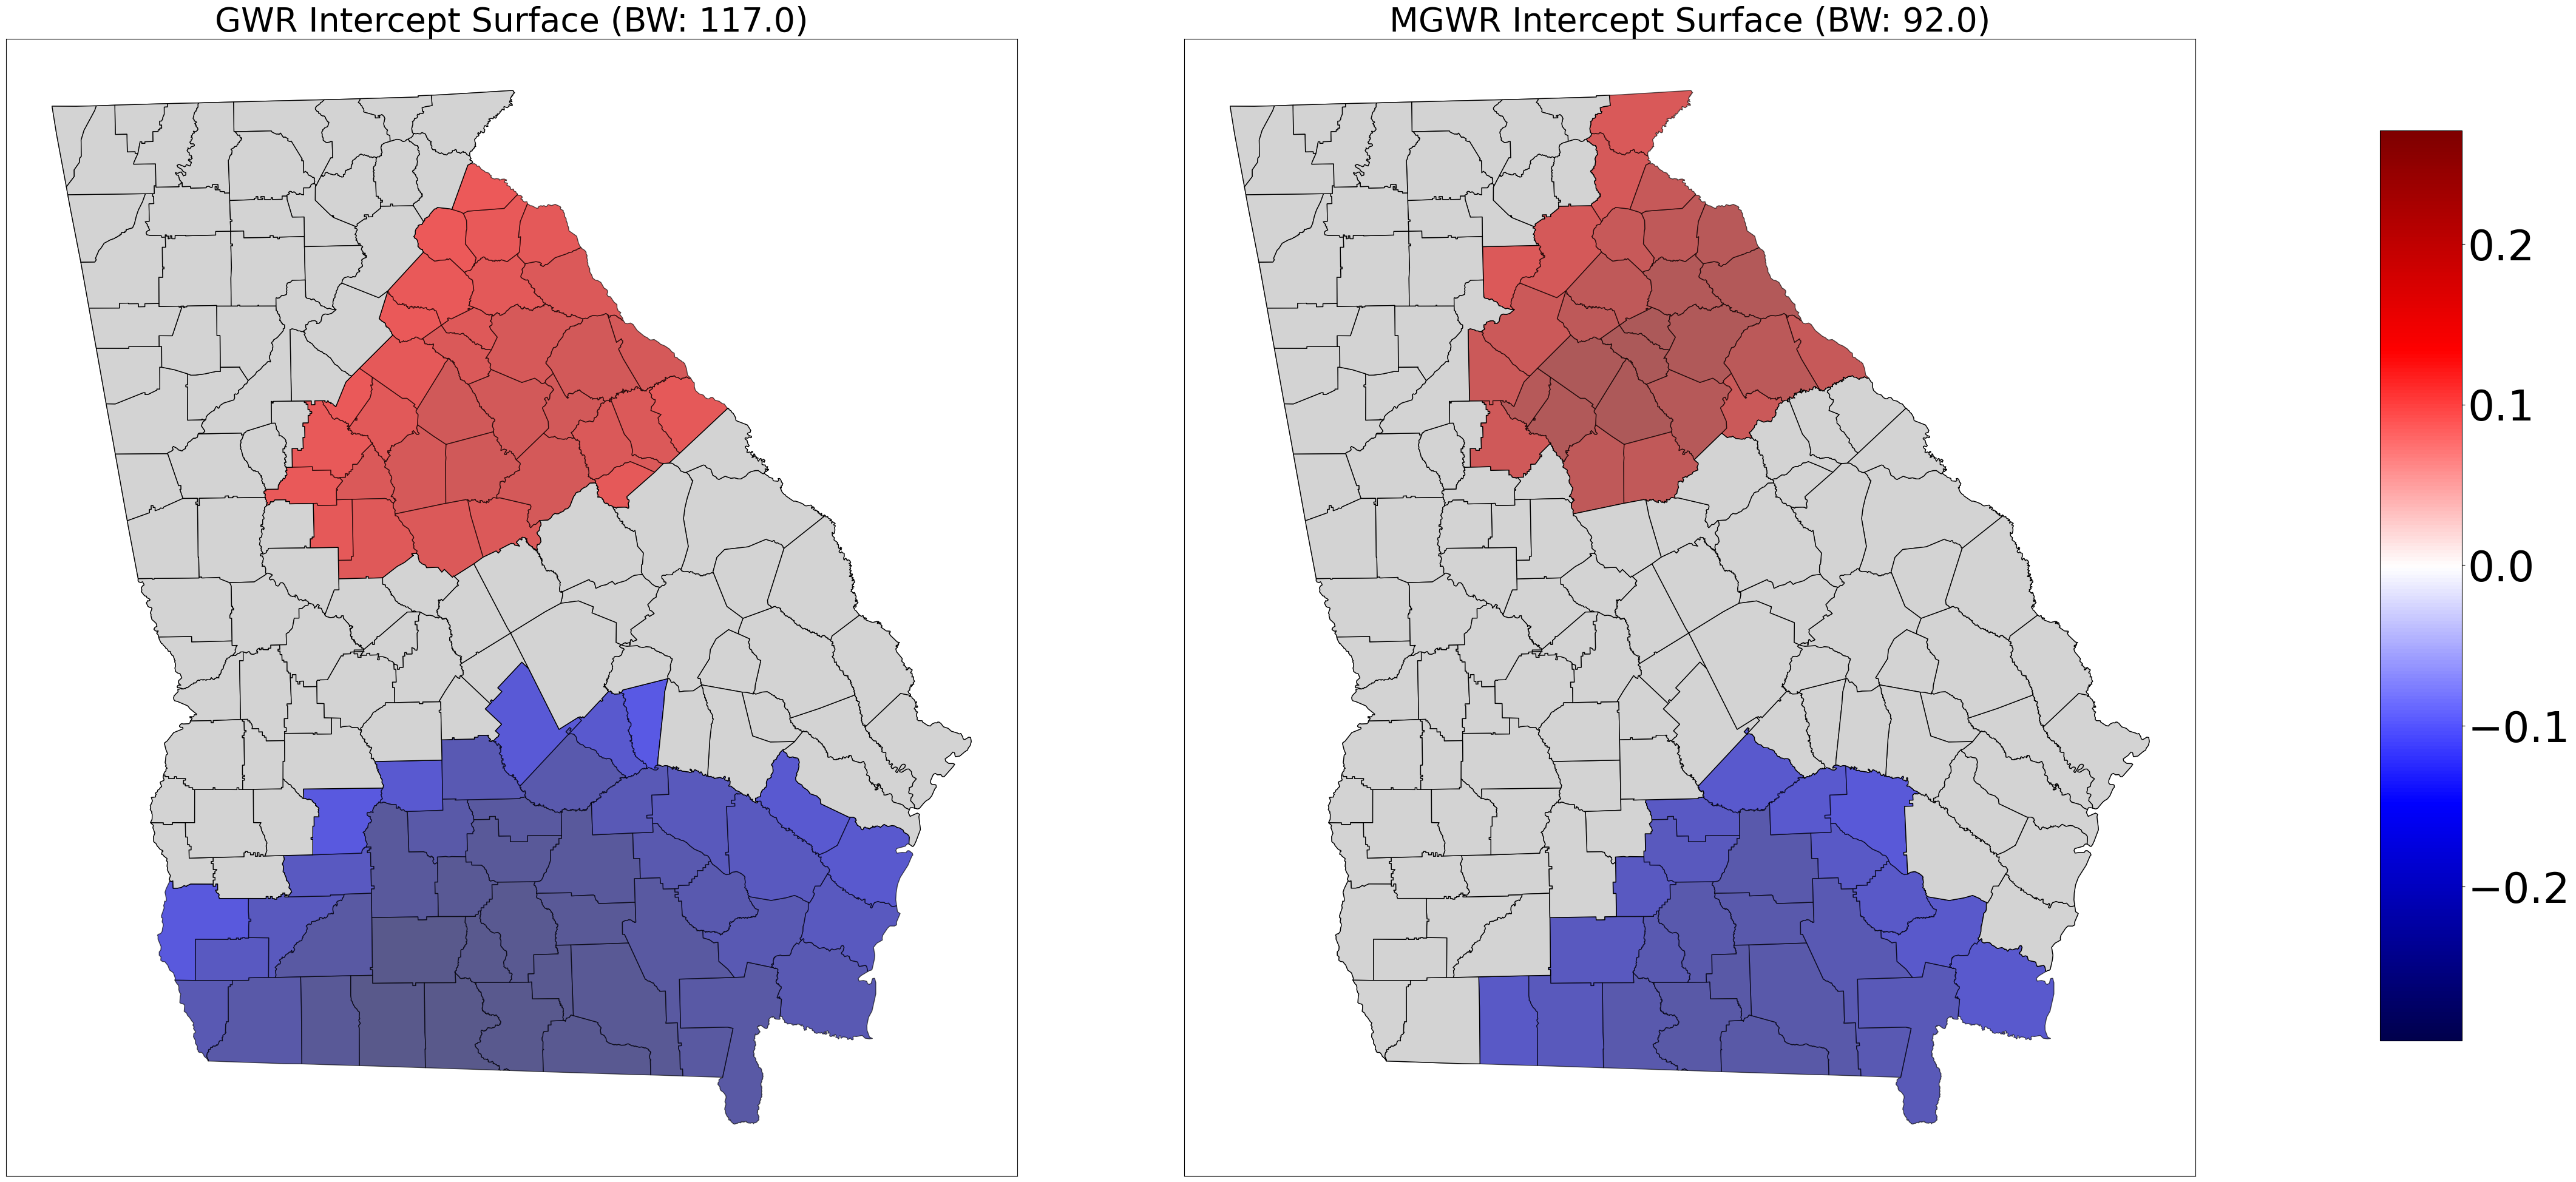

In [ ]:
#Comparison maps of GWR vs. MGWR parameter surfaces where the grey units pertain to statistically insignificant parameters

from mgwr.utils import shift_colormap, truncate_colormap
if not hasattr(plt, 'register_cmap'):
    plt.register_cmap = lambda name=None, cmap=None, **kw: plt.matplotlib.colormaps.register(cmap, name=name or cmap.name, force=True)


#Prep plot and add axes
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(45,20))
ax0 = axes[0]
ax0.set_title('GWR Intercept Surface (BW: ' + str(gwr_bw) +')', fontsize=40)
ax1 = axes[1]
ax1.set_title('MGWR Intercept Surface (BW: ' + str(mgwr_bw[0]) +')', fontsize=40)

#Set color map
cmap = plt.cm.seismic

#Find min and max values of the two combined datasets
gwr_min = georgia_shp['gwr_intercept'].min()
gwr_max = georgia_shp['gwr_intercept'].max()
mgwr_min = georgia_shp['mgwr_intercept'].min()
mgwr_max = georgia_shp['mgwr_intercept'].max()
vmin = np.min([gwr_min, mgwr_min])
vmax = np.max([gwr_max, mgwr_max])

#If all values are negative use the negative half of the colormap
if (vmin < 0) & (vmax < 0):
    cmap = truncate_colormap(cmap, 0.0, 0.5)
#If all values are positive use the positive half of the colormap
elif (vmin > 0) & (vmax > 0):
    cmap = truncate_colormap(cmap, 0.5, 1.0)
#Otherwise, there are positive and negative values so the colormap so zero is the midpoint
else:
    cmap = shift_colormap(cmap, start=0.0, midpoint=1 - vmax/(vmax + abs(vmin)), stop=1.)

#Create scalar mappable for colorbar and stretch colormap across range of data values
sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=vmin, vmax=vmax))

#Plot GWR parameters
georgia_shp.plot('gwr_intercept', cmap=sm.cmap, ax=ax0, vmin=vmin, vmax=vmax, **{'edgecolor':'black', 'alpha':.65})
#If there are insignificnt parameters plot gray polygons over them
if (gwr_filtered_t[:,0] == 0).any():
    georgia_shp[gwr_filtered_t[:,0] == 0].plot(color='lightgrey', ax=ax0, **{'edgecolor':'black'})

#Plot MGWR parameters
georgia_shp.plot('mgwr_intercept', cmap=sm.cmap, ax=ax1, vmin=vmin, vmax=vmax, **{'edgecolor':'black', 'alpha':.65})
#If there are insignificnt parameters plot gray polygons over them
if (mgwr_filtered_t[:,0] == 0).any():
    georgia_shp[mgwr_filtered_t[:,0] == 0].plot(color='lightgrey', ax=ax1, **{'edgecolor':'black'})
 
#Set figure options and plot 
fig.tight_layout()    
fig.subplots_adjust(right=0.9)
cax = fig.add_axes([0.92, 0.14, 0.03, 0.75])
sm._A = []
cbar = fig.colorbar(sm, cax=cax)
cbar.ax.tick_params(labelsize=50) 
ax0.get_xaxis().set_visible(False)
ax0.get_yaxis().set_visible(False)
ax1.get_xaxis().set_visible(False)
ax1.get_yaxis().set_visible(False)
plt.show()

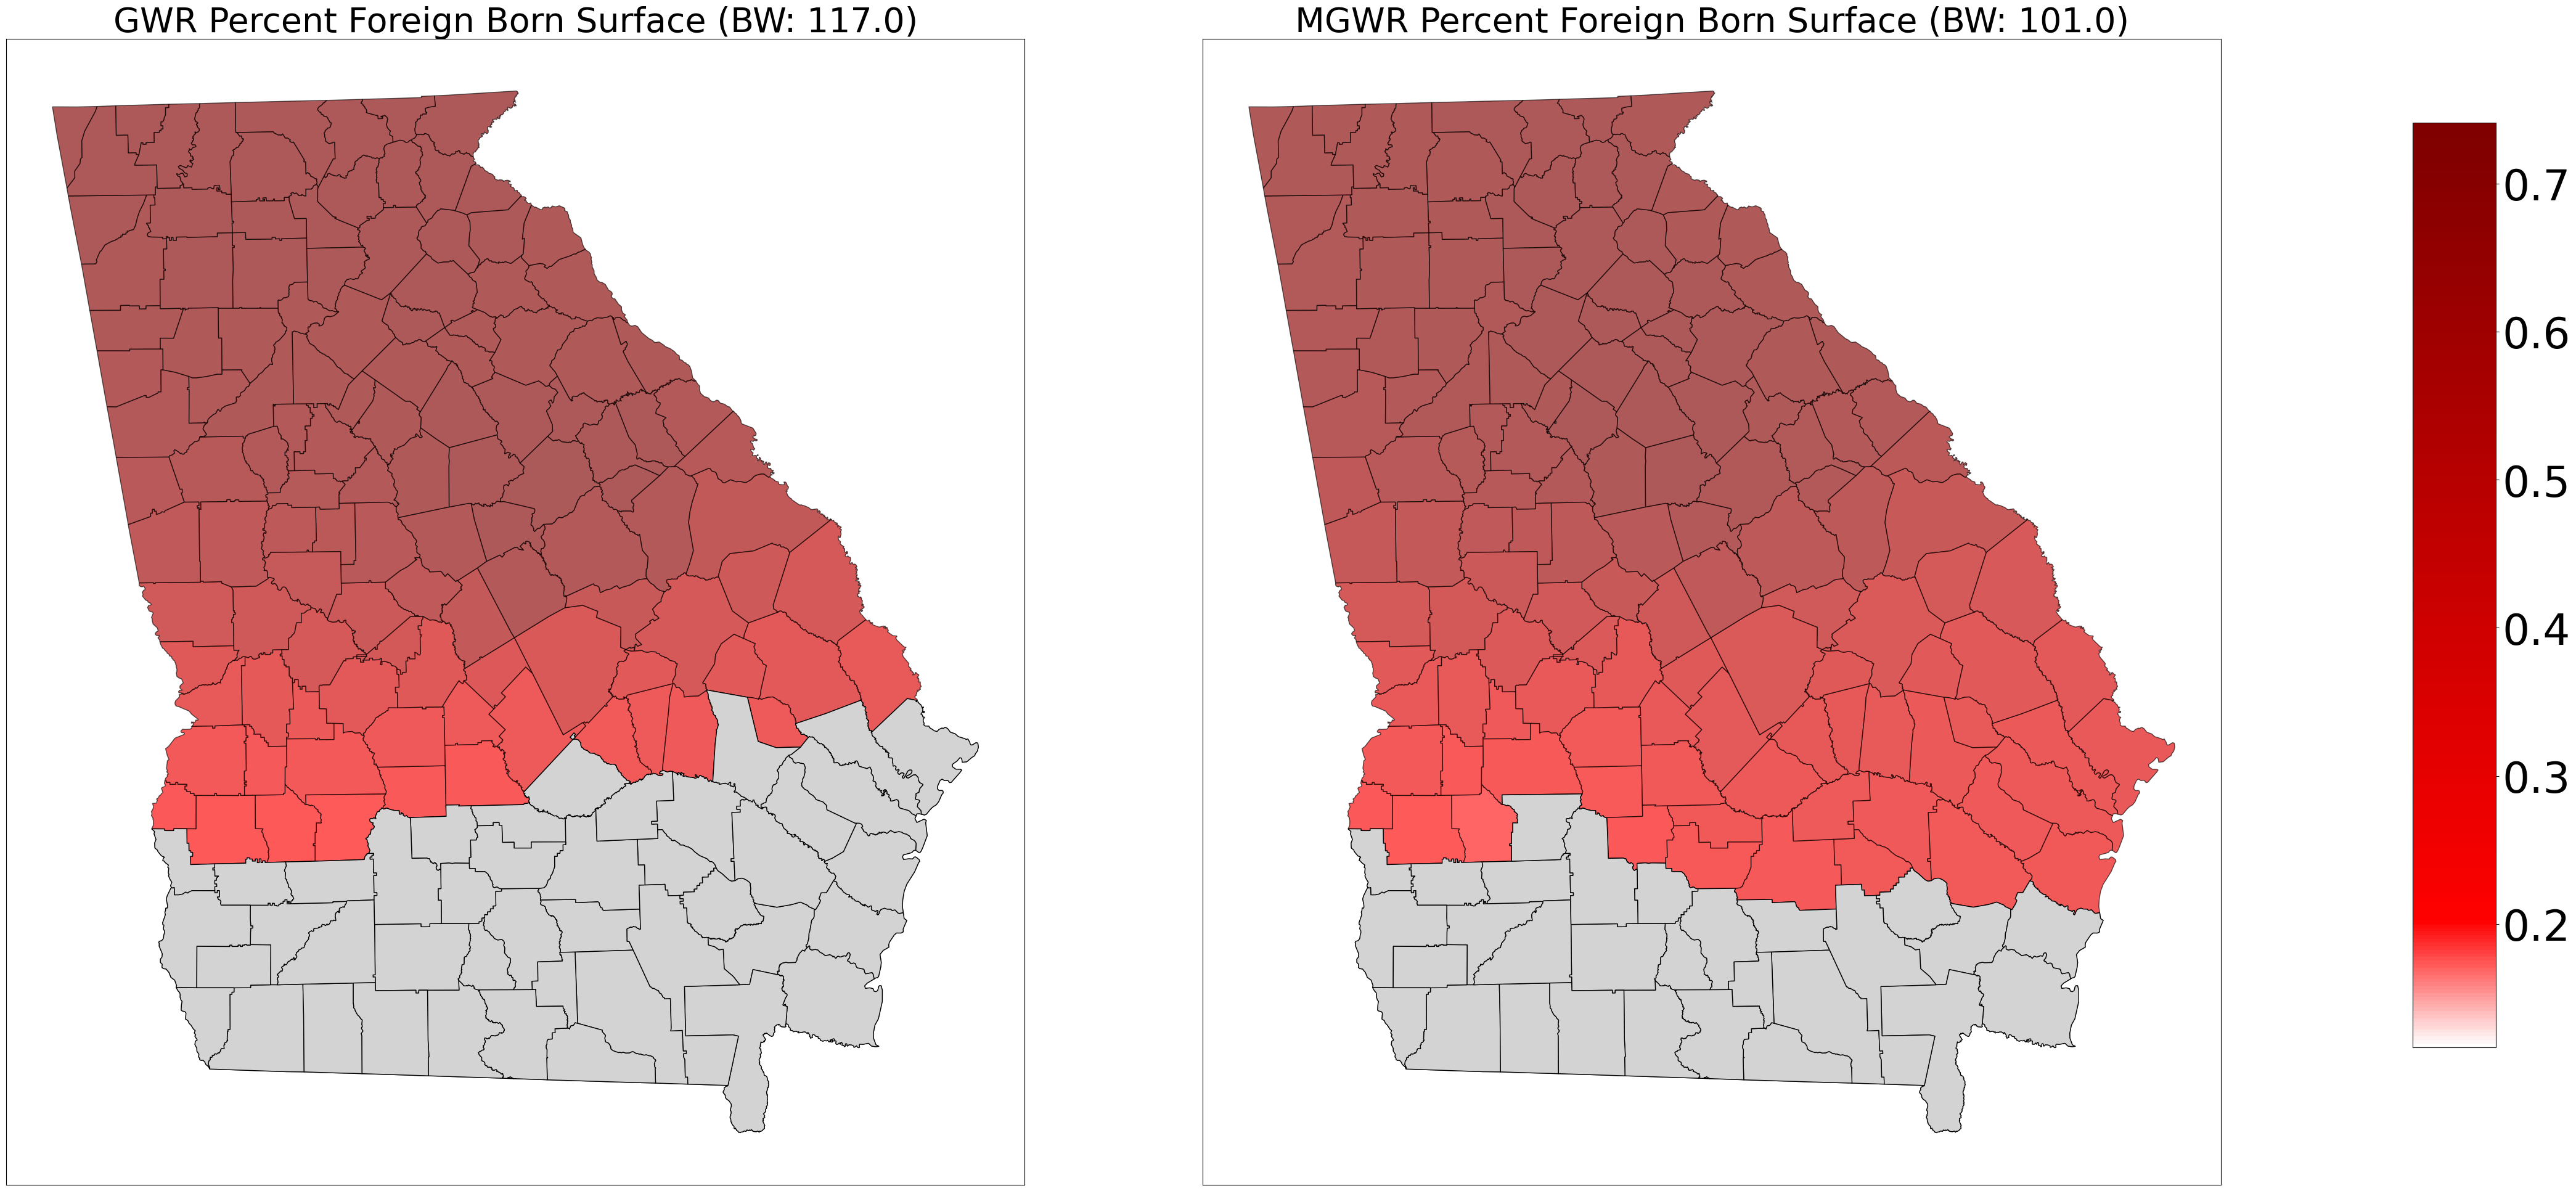

In [ ]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(45,20))
ax0 = axes[0]
ax0.set_title('GWR Percent Foreign Born Surface (BW: ' + str(gwr_bw) +')', fontsize=40)
ax1 = axes[1]
ax1.set_title('MGWR Percent Foreign Born Surface (BW: ' + str(mgwr_bw[1]) +')', fontsize=40)
cmap = plt.cm.seismic
gwr_min = georgia_shp['gwr_fb'].min()
gwr_max = georgia_shp['gwr_fb'].max()
mgwr_min = georgia_shp['mgwr_fb'].min()
mgwr_max = georgia_shp['mgwr_fb'].max()
vmin = np.min([gwr_min, mgwr_min])
vmax = np.max([gwr_max, mgwr_max])

if (vmin < 0) & (vmax < 0):
    cmap = truncate_colormap(cmap, 0.0, 0.5)
elif (vmin > 0) & (vmax > 0):
    cmap = truncate_colormap(cmap, 0.5, 1.0)

# Cambiar el nombre del colormap para evitar duplicados
cmap = shift_colormap(cmap, start=0.0, midpoint=1 - vmax/(vmax + abs(vmin)), stop=1., name="shiftedcmap_" + str(np.random.randint(1000)))

sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=vmin, vmax=vmax))

georgia_shp.plot('gwr_fb', cmap=sm.cmap, ax=ax0, vmin=vmin, vmax=vmax, **{'edgecolor':'black', 'alpha':.65})
if (gwr_filtered_t[:,1] == 0).any():
    georgia_shp[gwr_filtered_t[:,1] == 0].plot(color='lightgrey', ax=ax0, **{'edgecolor':'black'})

georgia_shp.plot('mgwr_fb', cmap=sm.cmap, ax=ax1, vmin=vmin, vmax=vmax, **{'edgecolor':'black', 'alpha':.65})
if (mgwr_filtered_t[:,1] == 0).any():
    georgia_shp[mgwr_filtered_t[:,1] == 0].plot(color='lightgrey', ax=ax1, **{'edgecolor':'black'})

    
fig.tight_layout()    
fig.subplots_adjust(right=0.9)
cax = fig.add_axes([0.92, 0.14, 0.03, 0.75])
sm._A = []
cbar = fig.colorbar(sm, cax=cax)
cbar.ax.tick_params(labelsize=50) 
ax0.get_xaxis().set_visible(False)
ax0.get_yaxis().set_visible(False)
ax1.get_xaxis().set_visible(False)
ax1.get_yaxis().set_visible(False)
plt.show()

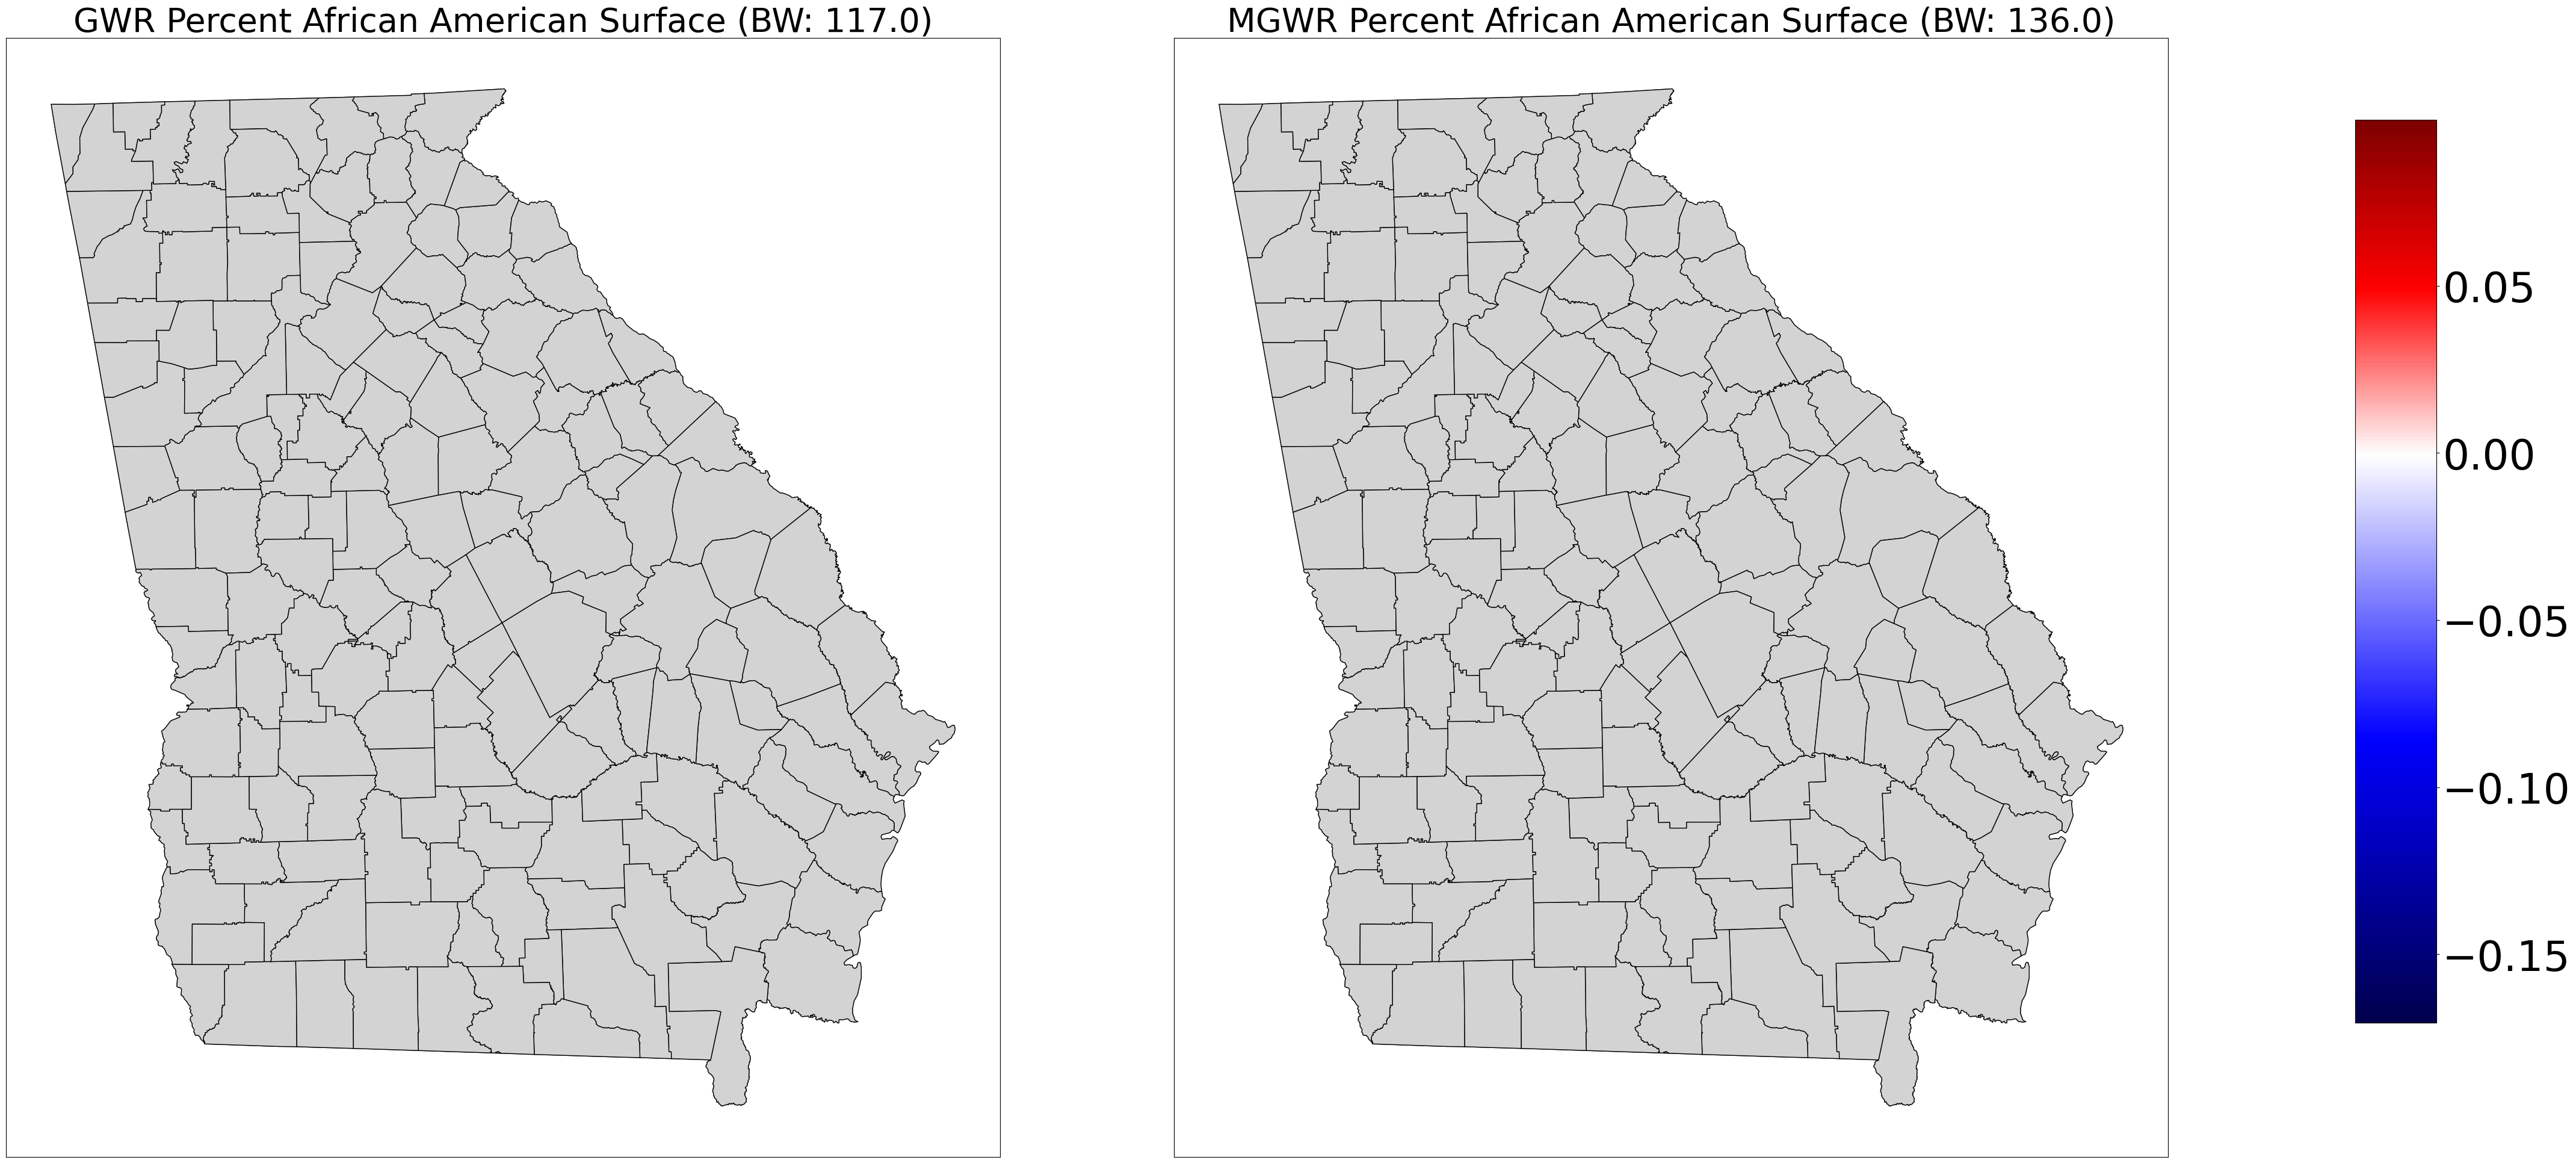

In [ ]:

# Crear la figura y los ejes
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(45, 20))

# Títulos para cada gráfico
ax0 = axes[0]
ax0.set_title('GWR Percent African American Surface (BW: ' + str(gwr_bw) + ')', fontsize=40)

ax1 = axes[1]
ax1.set_title('MGWR Percent African American Surface (BW: ' + str(mgwr_bw[2]) + ')', fontsize=40)

# Colormap inicial
cmap = plt.cm.seismic

# Definir valores mínimos y máximos
gwr_min = georgia_shp['gwr_aa'].min()
gwr_max = georgia_shp['gwr_aa'].max()
mgwr_min = georgia_shp['mgwr_aa'].min()
mgwr_max = georgia_shp['mgwr_aa'].max()

vmin = np.min([gwr_min, mgwr_min])
vmax = np.max([gwr_max, mgwr_max])

# Ajustar el colormap basado en los valores
if (vmin < 0) & (vmax < 0):
    cmap = truncate_colormap(cmap, 0.0, 0.5)
elif (vmin > 0) & (vmax > 0):
    cmap = truncate_colormap(cmap, 0.5, 1.0)
else:
    # Cambiar el nombre del colormap para evitar duplicados
    cmap = shift_colormap(cmap, start=0.0, midpoint=1 - vmax / (vmax + abs(vmin)), stop=1., name="shiftedcmap_" + str(np.random.randint(1000)))

# Crear el ScalarMappable
sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=vmin, vmax=vmax))

# Graficar el mapa de GWR
georgia_shp.plot('gwr_aa', cmap=sm.cmap, ax=ax0, vmin=vmin, vmax=vmax, **{'edgecolor': 'black', 'alpha': .65})
if (gwr_filtered_t[:, 2] == 0).any():
    georgia_shp[gwr_filtered_t[:, 2] == 0].plot(color='lightgrey', ax=ax0, **{'edgecolor': 'black'})

# Graficar el mapa de MGWR
georgia_shp.plot('mgwr_aa', cmap=sm.cmap, ax=ax1, vmin=vmin, vmax=vmax, **{'edgecolor': 'black', 'alpha': .65})
if (mgwr_filtered_t[:, 2] == 0).any():
    georgia_shp[mgwr_filtered_t[:, 2] == 0].plot(color='lightgrey', ax=ax1, **{'edgecolor': 'black'})

# Ajustar el diseño de la figura
fig.tight_layout()
fig.subplots_adjust(right=0.9)

# Añadir la barra de colores
cax = fig.add_axes([0.92, 0.14, 0.03, 0.75])
sm._A = []
cbar = fig.colorbar(sm, cax=cax)
cbar.ax.tick_params(labelsize=50)

# Ocultar ejes
ax0.get_xaxis().set_visible(False)
ax0.get_yaxis().set_visible(False)
ax1.get_xaxis().set_visible(False)
ax1.get_yaxis().set_visible(False)

# Mostrar la figura
plt.show()

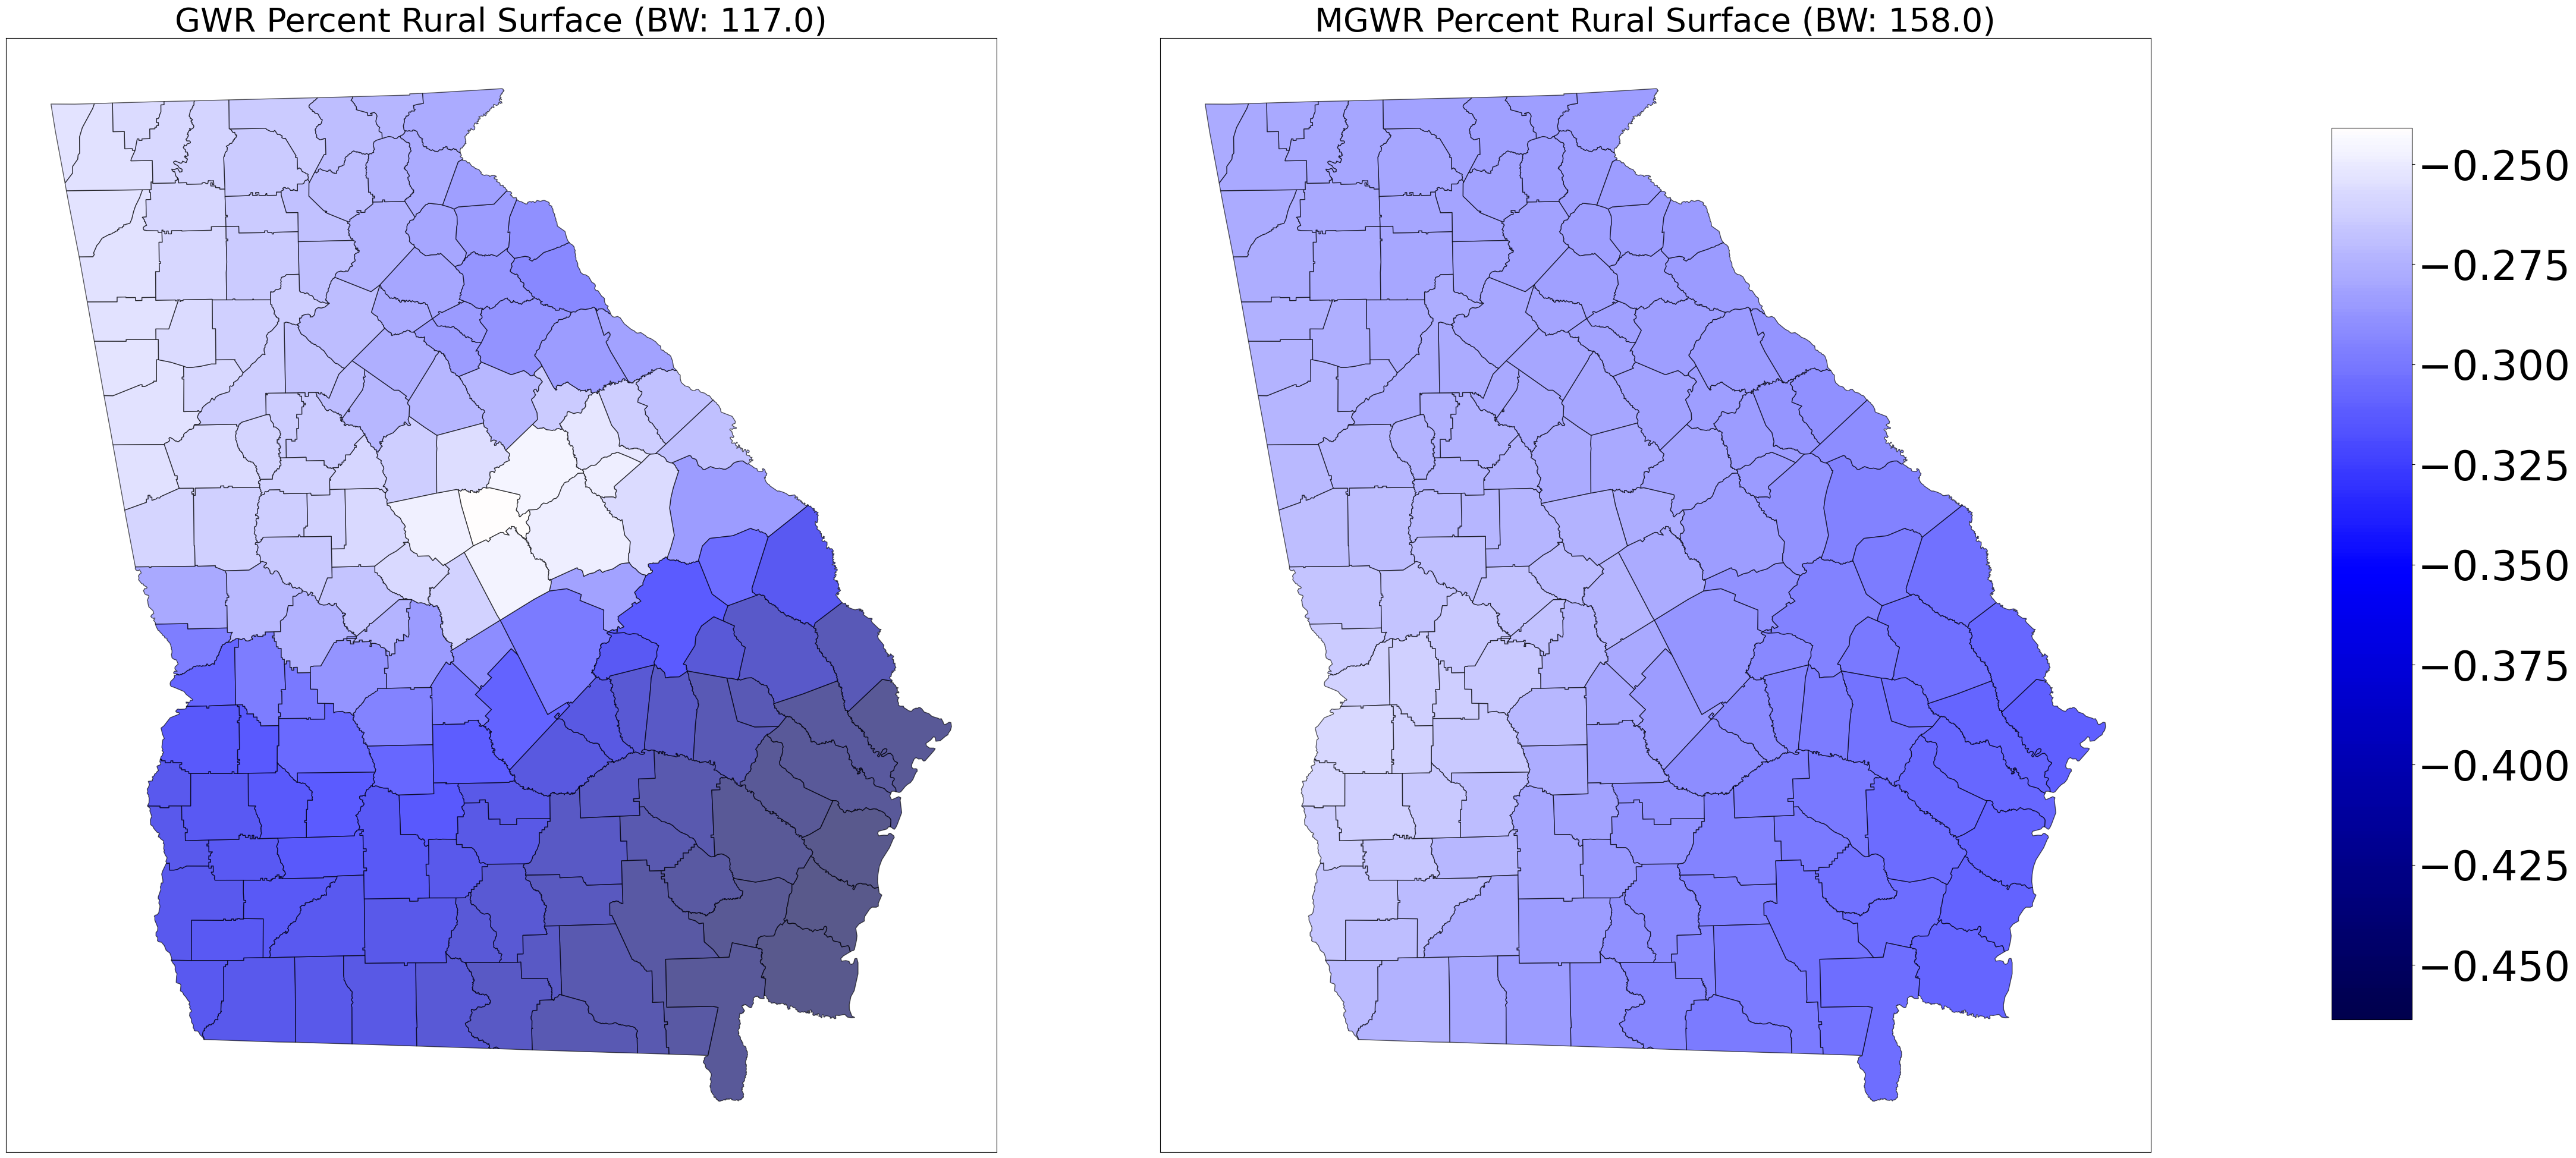

In [ ]:
# Crear la figura y los ejes
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(45, 20))

# Títulos para cada gráfico
ax0 = axes[0]
ax0.set_title('GWR Percent Rural Surface (BW: ' + str(gwr_bw) + ')', fontsize=40)

ax1 = axes[1]
ax1.set_title('MGWR Percent Rural Surface (BW: ' + str(mgwr_bw[3]) + ')', fontsize=40)

# Colormap inicial
cmap = plt.cm.seismic

# Definir valores mínimos y máximos
gwr_min = georgia_shp['gwr_rural'].min()
gwr_max = georgia_shp['gwr_rural'].max()
mgwr_min = georgia_shp['mgwr_rural'].min()
mgwr_max = georgia_shp['mgwr_rural'].max()

vmin = np.min([gwr_min, mgwr_min])
vmax = np.max([gwr_max, mgwr_max])

# Ajustar el colormap basado en los valores
if (vmin < 0) & (vmax < 0):
    cmap = truncate_colormap(cmap, 0.0, 0.5)
elif (vmin > 0) & (vmax > 0):
    cmap = truncate_colormap(cmap, 0.5, 1.0)
else:
    # Cambiar el nombre del colormap para evitar duplicados
    cmap = shift_colormap(cmap, start=0.0, midpoint=1 - vmax / (vmax + abs(vmin)), stop=1., name="shiftedcmap_" + str(np.random.randint(1000)))

# Crear el ScalarMappable
sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=vmin, vmax=vmax))

# Graficar el mapa de GWR
georgia_shp.plot('gwr_rural', cmap=sm.cmap, ax=ax0, vmin=vmin, vmax=vmax, **{'edgecolor': 'black', 'alpha': .65})
if (gwr_filtered_t[:, 3] == 0).any():
    georgia_shp[gwr_filtered_t[:, 3] == 0].plot(color='lightgrey', ax=ax0, **{'edgecolor': 'black'})

# Graficar el mapa de MGWR
georgia_shp.plot('mgwr_rural', cmap=sm.cmap, ax=ax1, vmin=vmin, vmax=vmax, **{'edgecolor': 'black', 'alpha': .65})
if (mgwr_filtered_t[:, 3] == 0).any():
    georgia_shp[mgwr_filtered_t[:, 3] == 0].plot(color='lightgrey', ax=ax1, **{'edgecolor': 'black'})

# Ajustar el diseño de la figura
fig.tight_layout()
fig.subplots_adjust(right=0.9)

# Añadir la barra de colores
cax = fig.add_axes([0.92, 0.14, 0.03, 0.75])
sm._A = []
cbar = fig.colorbar(sm, cax=cax)
cbar.ax.tick_params(labelsize=50)

# Ocultar ejes
ax0.get_xaxis().set_visible(False)
ax0.get_yaxis().set_visible(False)
ax1.get_xaxis().set_visible(False)
ax1.get_yaxis().set_visible(False)

# Mostrar la figura
plt.show()


También es posible probar la significancia estadística de cada superficie de estimaciones de parámetros producidas por GWR a través de métodos de Monte Carlo. La prueba de variabilidad espacial mezcla las observaciones en el espacio, recalibra GWR en los datos aleatorizados manteniendo constante la especificación del modelo, y luego calcula la variabilidad de las estimaciones de parámetros resultantes para cada superficie. Este proceso se repite y el número de veces que la variabilidad de cada superficie de los datos aleatorizados es mayor que la variabilidad de cada superficie original se utiliza para construir pseudo valores p para pruebas de hipótesis. Un pseudo valor-p menor que 0.05 indica que la variabilidad espacial observada de una superficie de coeficientes es significativa al nivel de confianza del 95% (es decir, no aleatoria).


In [ ]:
#Visualizing hypothesis tests for significance of parameter~estimates
#Manually set bandwidth to 107 and fit
gwr_model = GWR(g_coords, g_y, g_X, 107)
gwr_results = gwr_model.fit()

#default is 1000 iterations
p_vals_1000 = gwr_results.spatial_variability(gwr_selector)
print(p_vals_1000)

[0.002 0.091 0.166 0.553]


---
## Sección avanzada: Datos desde Google Earth Engine para GWR

**Google Earth Engine (GEE)** ofrece acceso a petabytes de imágenes satelitales procesadas en la nube y representa una de las fuentes de datos más potentes para análisis GWR a escala regional. Esta sección presenta un flujo de trabajo completo que integra GEE con `mgwr`, usando como caso de estudio la relación entre salud vegetal (NDVI), urbanización (NDBI) y topografía en **Castilla y León, España**.

> **Requisitos**: cuenta de GEE activa con proyecto configurado, y los paquetes:
> ```bash
> pip install earthengine-api geemap
> ```

**Flujo de trabajo en tres etapas:**

```
GEE (nube)                          │  Python local
────────────────────────────────────│────────────────────
Sentinel-2 + SRTM                   │
  ↓ Enmascarar nubes (S2_CLOUD_PROB)│
  ↓ Compuesto mediano (verano 2022) │
  ↓ Calcular NDVI, NDBI             │
  ↓ Generar 1000 puntos aleatorios  │
  ↓ sampleRegions() → FeatureCol.  │
  ──── geemap.ee_to_geopandas() ────→ GeoDataFrame
                                    │   ↓
                                    │ GWR/MGWR con mgwr
                                    │   ↓
                                    │ Mapas de coeficientes
```


In [ ]:
import ee
import geemap
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
from mgwr.gwr import GWR
from mgwr.sel_bw import Sel_BW
from sklearn.preprocessing import StandardScaler

# Autenticar e inicializar GEE (solo necesario la primera vez en cada entorno)
# Reemplazar 'your-project-id' con el ID de tu proyecto GEE
ee.Authenticate()
ee.Initialize(project='your-project-id')

In [ ]:
# ── Cargar colecciones desde el catálogo de GEE ──────────────────────────────
s2_sr    = ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')        # Sentinel-2 SR
s2_cloud = ee.ImageCollection('COPERNICUS/S2_CLOUD_PROBABILITY')    # Prob. de nube
dem      = ee.Image('USGS/SRTMGL1_003').select('elevation')         # DEM SRTM

# ── Área de interés: Castilla y León, España ──────────────────────────────────
admin = ee.FeatureCollection('FAO/GAUL/2015/level1')
aoi = admin.filter(
    ee.Filter.And(
        ee.Filter.eq('ADM0_NAME', 'Spain'),
        ee.Filter.eq('ADM1_NAME', 'Castilla y Leon')
    )
).geometry()

# ── Parámetros temporales y de calidad ────────────────────────────────────────
START_DATE     = '2022-06-01'   # verano: máxima cobertura vegetal
END_DATE       = '2022-08-31'
MAX_CLOUD_PROB = 65             # umbral de probabilidad de nube (%)

In [ ]:
# ── Filtrar colecciones por AOI y fecha ──────────────────────────────────────
s2_sr_f    = s2_sr.filterBounds(aoi).filterDate(START_DATE, END_DATE)
s2_cloud_f = s2_cloud.filterBounds(aoi).filterDate(START_DATE, END_DATE)

# ── Unir Sentinel-2 SR con su mapa de probabilidad de nube ───────────────────
s2_joined = ee.Join.saveFirst('cloud_mask').apply(
    primary=s2_sr_f,
    secondary=s2_cloud_f,
    condition=ee.Filter.equals(leftField='system:index',
                               rightField='system:index')
)

def mask_clouds(img):
    prob = ee.Image(img.get('cloud_mask')).select('probability')
    return img.updateMask(prob.lt(MAX_CLOUD_PROB))

# Compuesto mediano libre de nubes
composite = ee.ImageCollection(s2_joined).map(mask_clouds).median()

# ── Calcular índices espectrales ──────────────────────────────────────────────
# NDVI = (B8 - B4) / (B8 + B4)  → salud vegetal  (variable respuesta)
ndvi = composite.normalizedDifference(['B8', 'B4']).rename('NDVI')
# NDBI = (B11 - B8) / (B11 + B8) → densidad de área construida (predictor)
ndbi = composite.normalizedDifference(['B11', 'B8']).rename('NDBI')
# Remuestrear DEM a la proyección de Sentinel-2 (10 m)
elevation = dem.resample('bilinear').reproject(crs=ndvi.projection())

# ── Combinar en una imagen multibanda ─────────────────────────────────────────
analysis_img = ndvi.addBands(ndbi).addBands(elevation)
print('Bandas en analysis_img:', analysis_img.bandNames().getInfo())

In [ ]:
# ── Generar 1000 puntos aleatorios dentro del AOI ────────────────────────────
sample_pts = ee.FeatureCollection.randomPoints(
    region=aoi,
    points=1000,
    seed=42          # semilla para reproducibilidad
)

# ── Extraer valores de píxel en cada punto ────────────────────────────────────
sampled = analysis_img.sampleRegions(
    collection=sample_pts,
    properties=[],       # sin propiedades adicionales del vector
    scale=10,            # resolución Sentinel-2 (10 m)
    geometries=True      # conservar geometría de puntos
)

# ── Puente GEE → GeoPandas usando geemap ─────────────────────────────────────
# geemap.ee_to_geopandas() descarga el ee.FeatureCollection del servidor GEE
# y lo convierte directamente a un GeoDataFrame local, listo para PySAL.
# Este paso es la clave que conecta el ecosistema GEE con las herramientas locales.
gdf_gee = geemap.ee_to_geopandas(sampled)
gdf_gee = gdf_gee.dropna()
print(f'Puntos muestreados válidos: {len(gdf_gee)}')
print(gdf_gee[['NDVI', 'NDBI', 'elevation']].describe().round(4))

In [ ]:
# ── Preparar datos para GWR ───────────────────────────────────────────────────
coords_gee = list(zip(gdf_gee.geometry.x, gdf_gee.geometry.y))

# Variable respuesta: NDVI (Sentinel-2 SR está escalado x10000)
y_gee = (gdf_gee['NDVI'].values * 0.0001).reshape(-1, 1)

# Predictores: NDBI (escalado) + Elevación
X_gee = np.column_stack([
    gdf_gee['NDBI'].values * 0.0001,
    gdf_gee['elevation'].values
])

# Estandarizar (media=0, std=1) para comparar magnitudes de coeficientes
scaler_gee = StandardScaler()
X_gee_std = scaler_gee.fit_transform(X_gee)
y_gee_std = (y_gee - y_gee.mean()) / y_gee.std()

# ── Seleccionar ancho de banda óptimo (kernel adaptativo bisquare) ────────────
selector_gee = Sel_BW(coords_gee, y_gee_std, X_gee_std,
                      kernel='bisquare', fixed=False)
bw_gee = selector_gee.search()
print(f'Ancho de banda adaptativo óptimo: {bw_gee} vecinos')

# ── Ajustar GWR ───────────────────────────────────────────────────────────────
gwr_gee = GWR(coords_gee, y_gee_std, X_gee_std, bw_gee,
              kernel='bisquare', fixed=False).fit()
print(gwr_gee.summary())

In [ ]:
# ── Visualizar resultados GWR sobre datos GEE ────────────────────────────────
gdf_gee['gwr_localR2']    = gwr_gee.localR2.flatten()
gdf_gee['coef_ndbi']      = gwr_gee.params[:, 1]
gdf_gee['coef_elevation'] = gwr_gee.params[:, 2]

# Filtrar coeficientes estadísticamente significativos
# (corrección por pruebas múltiples, Bonferroni)
filtered_t_gee = gwr_gee.filter_tvals()
gdf_gee['ndbi_sig']      = filtered_t_gee[:, 1] != 0
gdf_gee['elevation_sig'] = filtered_t_gee[:, 2] != 0

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# R² local
gdf_gee.plot(column='gwr_localR2', cmap='viridis', ax=axes[0], legend=True,
             legend_kwds={'shrink': 0.6, 'label': 'R² local'})
axes[0].set_title('R² local (GWR)', fontsize=13)
axes[0].set_axis_off()

# Coeficiente NDBI — gris donde no es significativo
gdf_gee.plot(column='coef_ndbi', cmap='coolwarm', ax=axes[1], legend=True,
             legend_kwds={'shrink': 0.6})
gdf_gee[~gdf_gee['ndbi_sig']].plot(color='lightgrey', ax=axes[1],
                                    markersize=5, alpha=0.7)
axes[1].set_title('Coef. NDBI\n(gris = no significativo)', fontsize=13)
axes[1].set_axis_off()

# Coeficiente Elevación — gris donde no es significativo
gdf_gee.plot(column='coef_elevation', cmap='coolwarm', ax=axes[2], legend=True,
             legend_kwds={'shrink': 0.6})
gdf_gee[~gdf_gee['elevation_sig']].plot(color='lightgrey', ax=axes[2],
                                         markersize=5, alpha=0.7)
axes[2].set_title('Coef. Elevación\n(gris = no significativo)', fontsize=13)
axes[2].set_axis_off()

plt.suptitle('GWR — Castilla y León: NDVI ~ NDBI + Elevación (Sentinel-2)',
             fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

### Ejemplo con datos de cuencas de la implementación de GWR en *Python*

In [2]:
import numpy as np
import geopandas as gpd
from sklearn.preprocessing import StandardScaler
from mgwr.gwr import GWR, MGWR
from mgwr.sel_bw import Sel_BW
from matplotlib_scalebar.scalebar import ScaleBar
from mpl_toolkits.axes_grid1 import make_axes_locatable
from tabulate import tabulate
np.float = float 

In [3]:
# Load the dataset
import requests
from io import BytesIO

url = "https://github.com/edieraristizabal/ModeloMultinivel/raw/refs/heads/main/DATA/df_catchments_spatial.gpkg"

try:
    response = requests.get(url, stream=True)
    response.raise_for_status()  # Lanza una excepción para errores HTTP

    # Lee el contenido descargado como un archivo en memoria
    with BytesIO(response.content) as f:
        gdf = gpd.read_file(f)

    gdf.info()

except requests.exceptions.RequestException as e:
    print(f"Error al descargar el archivo: {e}")
except Exception as e:
    print(f"Error al leer el archivo GPKG: {e}")

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 526 entries, 0 to 525
Data columns (total 20 columns):
 #   Column               Non-Null Count  Dtype   
---  ------               --------------  -----   
 0   id                   526 non-null    int64   
 1   Nombre               526 non-null    object  
 2   ID_CUENCA            526 non-null    float64 
 3   cuenca               526 non-null    object  
 4   area                 526 non-null    int64   
 5   elev_mean            526 non-null    float64 
 6   elev_median          526 non-null    float64 
 7   rel_mean             526 non-null    float64 
 8   rel_median           526 non-null    float64 
 9   rainfallAnnual_mean  526 non-null    float64 
 10  Densidad             526 non-null    float64 
 11  hypso_inte           526 non-null    float64 
 12  slope_mean           526 non-null    float64 
 13  kmeans               526 non-null    object  
 14  RainfallDaysmean     526 non-null    float64 
 15  RainfallDaysmed

In [4]:
# Calculate landslide frequency as landslides per unit area
gdf['y_log'] = np.log(gdf['lands_rec'] + 1)
g_y = gdf['y_log'].values.reshape(-1, 1)

In [5]:
#definir coordenadas como puntos
u = gdf.centroid.x
v = gdf.centroid.y
g_coords = list(zip(u, v))

In [6]:
# Select optimal bandwidth for GWR model using coordinates, response, and predictors
variables = ['elev_mean', 'rel_mean',"rainfallAnnual_mean"]
scaler = StandardScaler()
g_X_num = scaler.fit_transform(gdf[variables])


En siguiente código permite implementar el modelo GWR utilizando una función kernel gaussiana y un distancia fija de 10km.

In [7]:
# Fit GWR model using the current bandwidth
model = GWR(g_coords, g_y, g_X_num, 10000, kernel='gaussian',fixed=True).fit()
model.summary()

Model type                                                         Gaussian
Number of observations:                                                 526
Number of covariates:                                                     4

Global Regression Results
---------------------------------------------------------------------------
Residual sum of squares:                                            807.013
Log-likelihood:                                                    -858.936
AIC:                                                               1725.872
AICc:                                                              1727.987
BIC:                                                              -2463.474
R2:                                                                   0.375
Adj. R2:                                                              0.371

Variable                              Est.         SE  t(Est/SE)    p-value
------------------------------- ---------- ---------- ------

Si se desea mantener la distancia variable y fijar el número de vecinos a 5, se utiliza el siguiente código.

In [8]:
# Fit GWR model using a fixed number of neighbors (adaptive bandwidth)
model = GWR(g_coords, g_y, g_X_num, 5, kernel='gaussian',fixed=False).fit()
model.summary()

Model type                                                         Gaussian
Number of observations:                                                 526
Number of covariates:                                                     4

Global Regression Results
---------------------------------------------------------------------------
Residual sum of squares:                                            807.013
Log-likelihood:                                                    -858.936
AIC:                                                               1725.872
AICc:                                                              1727.987
BIC:                                                              -2463.474
R2:                                                                   0.375
Adj. R2:                                                              0.371

Variable                              Est.         SE  t(Est/SE)    p-value
------------------------------- ---------- ---------- ------

Cuandos e desea utilizar el MGWR, se utiliza la función sel_BW que optimiza los valores del *bandwith*. Cuando *fixed=False*, el resultado de selector.bw será el número óptimo de vecinos. Cuando fixed=True, el resultado de selector.bw será la distancia óptima. Es importante ser consistente con el valor del parámetro fixed tanto al instanciar Sel_BW como al crear el modelo MGWR.

In [9]:
gwr_selector = Sel_BW(g_coords, g_y, g_X_num, multi=True, kernel='bisquare', fixed=True)
selector = gwr_selector.search()
print(selector)

Backfitting:   0%|          | 0/200 [00:00<?, ?it/s]

[ 58110.35  26662.34 689388.04 689386.48]


In [10]:
# Fit the MGWR model using the selected bandwidths
model = MGWR(g_coords, g_y, g_X_num, gwr_selector, kernel='bisquare', fixed=True).fit()
model.summary()

Inference:   0%|          | 0/1 [00:00<?, ?it/s]

Model type                                                         Gaussian
Number of observations:                                                 526
Number of covariates:                                                     4

Global Regression Results
---------------------------------------------------------------------------
Residual sum of squares:                                            807.013
Log-likelihood:                                                    -858.936
AIC:                                                               1725.872
AICc:                                                              1727.987
BIC:                                                              -2463.474
R2:                                                                   0.375
Adj. R2:                                                              0.371

Variable                              Est.         SE  t(Est/SE)    p-value
------------------------------- ---------- ---------- ------

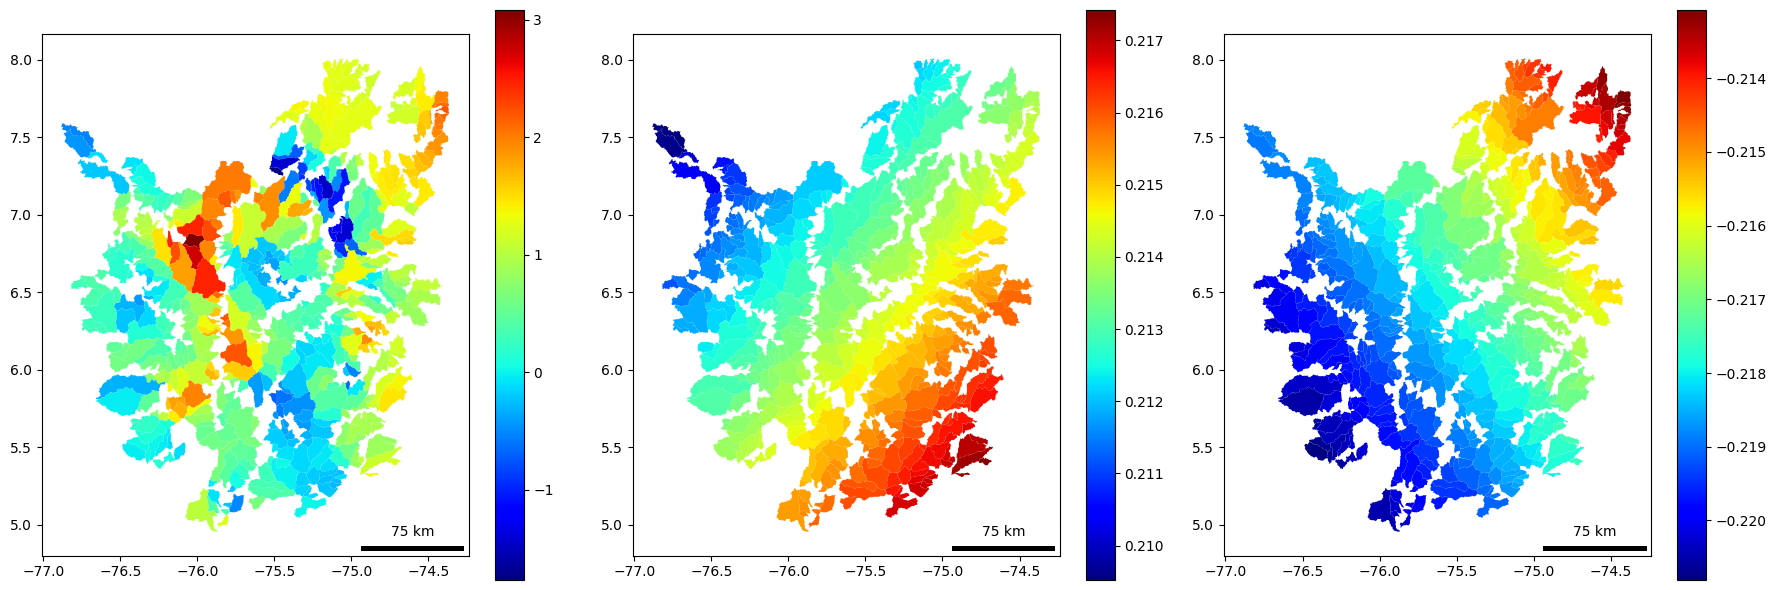

In [14]:
# Extract and plot the local coefficients for each covariate
local_params = model.params

# Create a single plot with three columns for each covariate (elevation, relief, and rainfall)
param_names = ['elev_mean', 'rel_mean', 'rainfallAnnual_mean']
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Transform geometries to WGS84 (EPSG:4326) before plotting
data_clean = gdf.to_crs(epsg=4326)

for i, param_name in enumerate(param_names):
    ax = axes[i]
    data_clean[f'coef_{param_name}'] = local_params[:, i+1] #tengo +1 para qeu no considere el primer coeficiente que pertenece al intercepto
    data_clean.plot(column=f'coef_{param_name}', ax=ax, cmap=plt.cm.jet, legend=True)
    scalebar = ScaleBar(111319.49079327357, "m", location='lower right', scale_loc='top', length_fraction=0.25, font_properties={"size": 10})
    ax.add_artist(scalebar)
    
# Save the entire figure with all three subplots
plt.tight_layout()
plt.show()

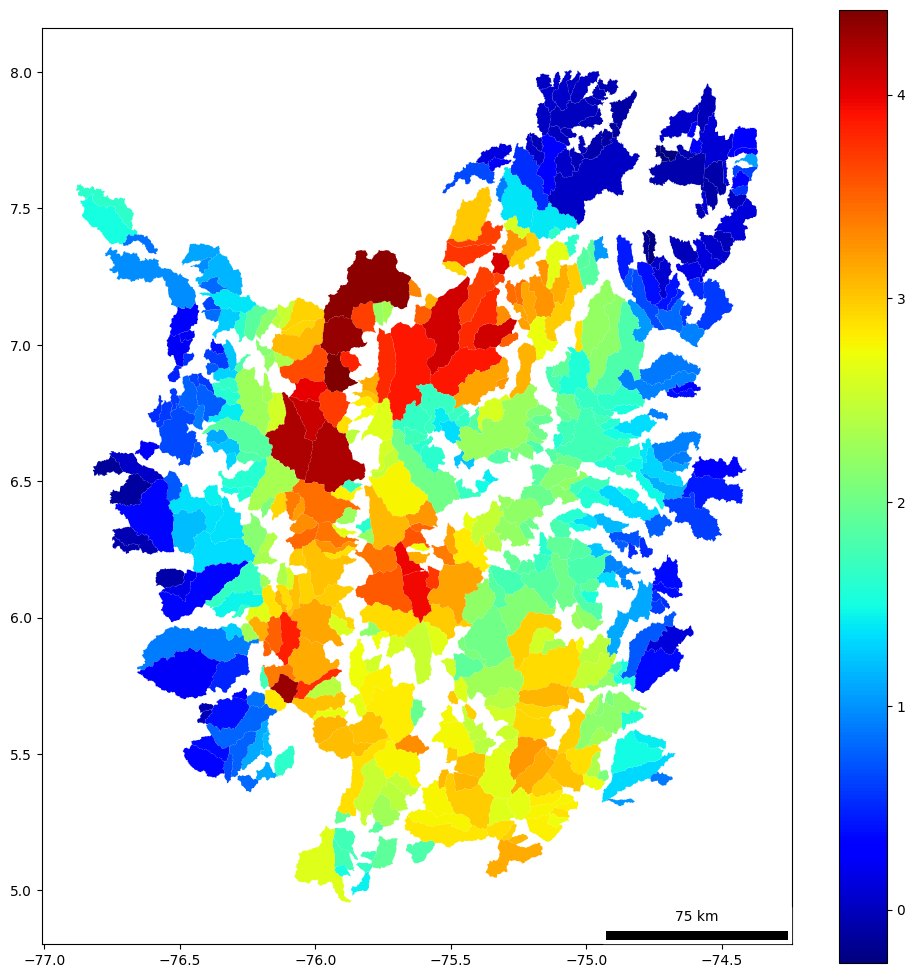

In [15]:
# Assuming model is the fitted MGWR model object
fig, ax = plt.subplots(figsize=(10, 10))
data_clean["fitted"] = model.predy  # The predicted values (fitted values) from the MGWR model
data_clean.plot(column="fitted", ax=ax, cmap=plt.cm.jet, legend=True)
scalebar = ScaleBar(111319.49079327357, "m", location='lower right', scale_loc='top', length_fraction=0.25, font_properties={"size": 10})
ax.add_artist(scalebar)
plt.tight_layout()
plt.show()

In [ ]:
# ── R² local del MGWR — dataset de cuencas ──────────────────────────────────
# El R² local indica qué fracción de la varianza de deslizamientos explica
# el modelo en cada cuenca, a diferencia del R² único del OLS global.
data_clean['mgwr_localR2'] = model.localR2.flatten()

fig, ax = plt.subplots(figsize=(10, 8))
data_clean.plot(column='mgwr_localR2', cmap='YlOrRd',
                scheme='quantiles', k=5, legend=True, ax=ax,
                legend_kwds={'title': 'R² local MGWR', 'loc': 'lower left'})
ax.set_title('MGWR: R² local — Cuencas Andinas\n(Atrato, Cauca, Magdalena)',
             fontsize=14)
ax.set_axis_off()
from matplotlib_scalebar.scalebar import ScaleBar
ax.add_artist(ScaleBar(111319.49, 'm', location='lower right',
                       scale_loc='top', length_fraction=0.25,
                       font_properties={'size': 10}))
plt.tight_layout()
plt.show()

print(f"R² local  min: {data_clean['mgwr_localR2'].min():.3f} | "
      f"media: {data_clean['mgwr_localR2'].mean():.3f} | "
      f"max: {data_clean['mgwr_localR2'].max():.3f}")

In [ ]:
# ── Significancia estadística de coeficientes locales (cuencas) ──────────────
# filter_tvals() aplica corrección de Bonferroni para pruebas múltiples.
# Las celdas grises indican zonas donde el coeficiente no es significativo.
# Columnas en model.params: [intercepto, elev_mean, rel_mean, rainfallAnnual_mean]

mgwr_t       = model.filter_tvals()
param_names  = ['elev_mean', 'rel_mean', 'rainfallAnnual_mean']
param_labels = ['Elevación media', 'Relieve relativo', 'Días de lluvia anual']

fig, axes = plt.subplots(1, 3, figsize=(19, 6))

for i, (name, label) in enumerate(zip(param_names, param_labels)):
    ax      = axes[i]
    col     = f'mgwr_coef_{name}'
    data_clean[col] = model.params[:, i + 1]
    is_sig  = mgwr_t[:, i + 1] != 0

    # Todos los coeficientes con gradiente de color
    data_clean.plot(column=col, cmap='coolwarm', ax=ax, legend=True,
                    legend_kwds={'shrink': 0.6})
    # Superponer en gris los coeficientes no significativos
    data_clean[~is_sig].plot(color='lightgrey', ax=ax,
                              edgecolor='white', linewidth=0.3)
    n_sig = int(is_sig.sum())
    pct   = 100 * n_sig / len(data_clean)
    ax.set_title(f'{label}\n({n_sig}/{len(data_clean)} sig. = {pct:.0f}%)',
                 fontsize=11)
    ax.set_axis_off()

plt.suptitle('MGWR: Coeficientes locales significativos — Cuencas Andinas',
             fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

## Consideraciones avanzadas y diagnósticos

### Multicolinealidad local

Al igual que en los modelos globales, el GWR puede sufrir **multicolinealidad local**: predictores altamente correlacionados dentro de sub-regiones específicas del área de estudio, aunque no lo estén globalmente. Esto produce estimaciones inestables en esas zonas. El **número de condición local** es el diagnóstico recomendado:

```python
# Valores > 30 sugieren multicolinealidad local problemática
gdf['cond_number'] = gwr_results.cond_number
gdf.plot(column='cond_number', cmap='Reds', legend=True)
```

### GWR como herramienta exploratoria

El GWR es principalmente una técnica **exploratoria**. Su fortaleza reside en identificar patrones espaciales y generar hipótesis sobre procesos subyacentes. Su uso como herramienta predictiva en localizaciones nuevas es más controvertido y debe abordarse con precaución.

### El problema de la escala: motivación del MGWR

Una limitación clave del GWR clásico es que asume que **todas las relaciones operan a la misma escala espacial**, definida por un único BW óptimo. En la realidad, diferentes procesos tienen distintas huellas espaciales:

| Variable | Proceso | Escala esperada |
|----------|---------|----------------|
| Precipitación anual | Circulación atmosférica regional | Grande (BW amplio) |
| Pendiente media | Topografía local de cada cuenca | Pequeña (BW estrecho) |
| Relieve relativo | Disección fluvial y morfología | Intermedia |

**MGWR** asigna a cada predictor su propio BW óptimo, produciendo un modelo más realista. Los anchos de banda obtenidos son en sí mismos un resultado científico: revelan la **escala espacial** a la que opera cada proceso geomorfológico.

### Comparación OLS vs. GWR: ¿cuándo justifica la complejidad adicional?

| Métrica | OLS global | GWR / MGWR local |
|---------|-----------|------------------|
| AICc | Mayor | **Menor** (mejor ajuste) |
| R² ajustado | Menor | **Mayor** |
| Coeficientes | Únicos, globales | Superficies espacialmente variables |
| Interpretación | Simple | Rica en variación espacial |
| Costo computacional | Bajo | Alto |

Un AICc significativamente menor y un R² ajustado mayor en GWR, junto con residuos espacialmente no autocorrelacionados, son evidencia sólida de que la variación espacial de los coeficientes es real y no un artefacto del método.

### Referencias complementarias
- Brunsdon, C., Fotheringham, A. S., & Charlton, M. E. (1996). Geographically weighted regression: a method for exploring spatial nonstationarity. *Geographical Analysis*, 28(4), 281–298.
- Fotheringham, A. S., Brunsdon, C., & Charlton, M. (2002). *Geographically Weighted Regression: The Analysis of Spatially Varying Relationships*. Wiley.
- Fotheringham, A. S., Yang, W., & Kang, W. (2017). Multiscale Geographically Weighted Regression (MGWR). *Annals of the American Association of Geographers*, 107(6), 1247–1265.
- Oshan, T. M. et al. (2019). mgwr: A Python implementation of multiscale geographically weighted regression. *ISPRS International Journal of Geo-Information*, 8(6), 269.
- Tobler, W. R. (1970). A computer movie simulating urban growth in the Detroit region. *Economic Geography*, 46(sup1), 234–240.


## Actividades

1. **GWR vs. OLS:** Ajusta un GWR al dataset de cuencas para la variable respuesta `lands_rec` (transformada). Extrae los coeficientes locales de `slope_mean` y mapéalos. ¿En qué zonas el efecto de la pendiente es más fuerte? ¿Coincide con la distribución conocida de deslizamientos?

2. **Selección de ancho de banda:** Compara el AIC del GWR para al menos tres anchos de banda fijos (50, 100, 150 km) versus el ancho de banda óptimo seleccionado automáticamente por `Sel_BW`. ¿Cómo cambia la variación espacial de los coeficientes con el ancho de banda?

3. **Comparación GWR vs. MGWR:** Ajusta tanto el GWR como el MGWR al mismo dataset. Para cada covariable, compara el ancho de banda óptimo en MGWR. ¿Qué variable opera a una escala más local (ancho de banda pequeño) y cuál a una escala más regional (ancho de banda grande)? Interpreta este resultado geomorfológicamente.

4. **Significancia estadística de coeficientes locales:** Para el MGWR, identifica las subcuencas donde el coeficiente local de `RainfallDaysmean` es estadísticamente significativo (t > 1.96). Mapea estas subcuencas. ¿Representan un patrón geográfico coherente con las zonas de mayor precipitación?

## Recursos adicionales

### Documentación oficial
- [mgwr — Multiscale GWR (Python)](https://mgwr.readthedocs.io/)
- [GWR4 — Software oficial de Fotheringham](https://sgsup.asu.edu/sparc/gwr4)

### Lecturas recomendadas
- Fotheringham, A. S., Brunsdon, C., & Charlton, M. (2002). *Geographically Weighted Regression: The Analysis of Spatially Varying Relationships*. Wiley.
- Fotheringham, A. S., Yang, W., & Kang, W. (2017). Multiscale geographically weighted regression. *Annals of the American Association of Geographers*, 107(6), 1247–1265.
- Brunsdon, C., Fotheringham, A. S., & Charlton, M. (1996). Geographically weighted regression: A method for exploring spatial nonstationarity. *Geographical Analysis*, 28(4), 281–298.
- Wheeler, D. & Tiefelsdorf, M. (2005). Multicollinearity and correlation among local regression coefficients in geographically weighted regression. *Journal of Geographical Systems*, 7(2), 161–187.

### Tutoriales
- [mgwr — Python Tutorials](https://mgwr.readthedocs.io/en/latest/notebooks/Notebooks.html)
- [GWR en GeoDa](https://geodacenter.github.io/workbook/9b_gwr2/lab9b.html)